# VentiMorph-RelNet v2.8.1 — FINAL 20-Patient Locked Test + Complete Visualization

Use this notebook with the **same Kaggle Dataset containing all five completed Fold 0–4 outputs**.

## Kaggle inputs required
1. Your five-fold VentiMorph output dataset containing `best_model.pt` and `patient_level_5fold_split.csv` for Fold 0–4.
2. The original MS3SEG dataset.

## Accelerator
Use **GPU T4**.

The notebook auto-discovers all inputs. It does **not retrain or tune** anything. The frozen inference rule remains:

**five best fold checkpoints → equal-weight softmax ensemble → argmax**

It produces final patient/class Dice, lesion metrics, size-specific recall, HD95/ASSD, bootstrap 95% confidence intervals, confusion matrix, patient-wise plots, and supplementary locked-test ROC/PR/calibration curves from the frozen ensemble probabilities.


In [5]:
from __future__ import annotations

import os
import re
import gc
import io
import json
import math
import random
import warnings
import hashlib
import zipfile
import shutil
from functools import lru_cache
from pathlib import Path
from typing import Literal

import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt

from scipy import ndimage
from scipy.optimize import linear_sum_assignment

import torch
import torch.nn as nn
import torch.nn.functional as F

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
INFERENCE_BATCH_SIZE = 4
LOCKED_TEST_EVALUATION = True
EXPECTED_SPLIT_SHA256 = "d5b26261c93305d0554dae92454cee9363c8df5d946c944d47ab1b8a25898459"

OUTPUT_DIR = Path("/kaggle/working/ventimorph_v281_final_locked_test")
FIGURE_DIR = OUTPUT_DIR / "figures"
TABLE_DIR = OUTPUT_DIR / "tables"
PREDICTION_DIR = OUTPUT_DIR / "predictions"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)
PREDICTION_DIR.mkdir(parents=True, exist_ok=True)

print("Device:", DEVICE)
if DEVICE.type != "cuda":
    warnings.warn("A GPU is strongly recommended. Select a T4 GPU in Kaggle Settings.")

print("FINAL LOCKED-TEST MODE: ENABLED")


Device: cuda
FINAL LOCKED-TEST MODE: ENABLED


In [6]:

def discover_ms3seg_root():
    required = {"MS_100_patient_preprocessed", "MS_100_patient_masks"}

    preferred = [
        Path("/kaggle/input/ms3seg/MS3SEG"),
        Path("/kaggle/input/ms3seg"),
        Path("/kaggle/input/datasets/saifsamiul/ms3seg/MS3SEG"),
    ]

    for candidate in preferred:
        if not candidate.exists() or not candidate.is_dir():
            continue
        names = {p.name for p in candidate.iterdir() if p.is_dir()}
        if required.issubset(names):
            return candidate

    input_root = Path("/kaggle/input")
    for preprocessed in input_root.rglob("MS_100_patient_preprocessed"):
        candidate = preprocessed.parent
        if (candidate / "MS_100_patient_masks").exists():
            return candidate

    raise FileNotFoundError(
        "MS3SEG was not found. Attach the original MS3SEG Kaggle dataset "
        "in addition to your dataset containing the five fold outputs."
    )


def _normalized_name(text):
    return re.sub(r"[^a-z0-9]+", "", str(text).lower())


def discover_all_fold_bundles():
    """
    Supports either:
      1) one Kaggle Dataset containing five fold transfer ZIPs, or
      2) one Kaggle Dataset containing five already-extracted fold folders.

    The dataset name itself does not matter. Everything is auto-discovered
    under /kaggle/input.
    """
    input_root = Path("/kaggle/input")
    extraction_root = Path("/kaggle/working/v281_fivefold_extract")
    extraction_root.mkdir(parents=True, exist_ok=True)

    bundles = {}

    all_zips = [p for p in input_root.rglob("*.zip") if p.is_file()]

    for fold in range(5):
        token = f"fold{fold}"

        # -------- ZIP mode --------
        zip_candidates = []
        for p in all_zips:
            name = _normalized_name(p.name)
            if token not in name:
                continue
            # Prefer training-output/transfer archives, but accept any ZIP
            # that actually contains the required files.
            try:
                with zipfile.ZipFile(p, "r") as zf:
                    names = {Path(n).name for n in zf.namelist()}
                if {"best_model.pt", "patient_level_5fold_split.csv"}.issubset(names):
                    zip_candidates.append(p)
            except Exception:
                continue

        if zip_candidates:
            # Prefer names containing FULL60/TRANSFER, then larger archive.
            zip_candidates = sorted(
                zip_candidates,
                key=lambda p: (
                    ("full60" in _normalized_name(p.name)),
                    ("transfer" in _normalized_name(p.name)),
                    p.stat().st_size,
                ),
                reverse=True,
            )
            zip_path = zip_candidates[0]

            fold_dir = extraction_root / f"fold{fold}"
            if fold_dir.exists():
                shutil.rmtree(fold_dir)
            fold_dir.mkdir(parents=True, exist_ok=True)

            with zipfile.ZipFile(zip_path, "r") as zf:
                zf.extractall(fold_dir)

            # Locate files recursively because some ZIPs contain an outer folder.
            def find_extracted(filename, required=True):
                hits = list(fold_dir.rglob(filename))
                if required and not hits:
                    raise FileNotFoundError(
                        f"{filename} not found after extracting {zip_path}"
                    )
                return hits[0] if hits else None

            checkpoint = find_extracted("best_model.pt")
            split_path = find_extracted("patient_level_5fold_split.csv")
            metadata_path = find_extracted("transfer_metadata.json", required=False)
            history_path = find_extracted("history.csv", required=False)

            bundles[fold] = {
                "checkpoint": checkpoint,
                "split": split_path,
                "metadata": metadata_path,
                "history": history_path,
                "source": zip_path,
            }
            continue

        # -------- already-extracted mode --------
        direct_candidates = []
        for checkpoint in input_root.rglob("best_model.pt"):
            parent = checkpoint.parent
            split_path = parent / "patient_level_5fold_split.csv"
            metadata_path = parent / "transfer_metadata.json"
            history_path = parent / "history.csv"

            if not split_path.exists():
                continue

            inferred_fold = None
            if metadata_path.exists():
                try:
                    meta = json.loads(metadata_path.read_text(encoding="utf-8"))
                    if meta.get("fold") is not None:
                        inferred_fold = int(meta["fold"])
                    elif f"fold{fold}" in _normalized_name(meta.get("run_directory", "")):
                        inferred_fold = fold
                except Exception:
                    pass

            if inferred_fold is None:
                if token in _normalized_name(parent):
                    inferred_fold = fold

            if inferred_fold == fold:
                direct_candidates.append(
                    (checkpoint, split_path, metadata_path if metadata_path.exists() else None,
                     history_path if history_path.exists() else None)
                )

        if not direct_candidates:
            raise FileNotFoundError(
                f"Fold {fold} output was not found under /kaggle/input.\n"
                "Your five-fold dataset must contain, for each fold, at least:\n"
                "  best_model.pt\n"
                "  patient_level_5fold_split.csv\n"
                "Recommended additional file: history.csv"
            )

        checkpoint, split_path, metadata_path, history_path = direct_candidates[0]
        bundles[fold] = {
            "checkpoint": checkpoint,
            "split": split_path,
            "metadata": metadata_path,
            "history": history_path,
            "source": checkpoint.parent,
        }

    return bundles


DATA_ROOT = discover_ms3seg_root()
CHECKPOINT_BUNDLES = discover_all_fold_bundles()

PREPROCESSED_DIR = DATA_ROOT / "MS_100_patient_preprocessed"
MASKS_DIR = DATA_ROOT / "MS_100_patient_masks"

print("MS3SEG dataset root:", DATA_ROOT)
print("\nFive-fold model-output dataset:")
for fold, info in CHECKPOINT_BUNDLES.items():
    print(
        f"Fold {fold}: {info['source']} | "
        f"history={'YES' if info['history'] is not None else 'NO'}"
    )


MS3SEG dataset root: /kaggle/input/datasets/saifsamiul/ms3seg/MS3SEG

Five-fold model-output dataset:
Fold 0: /kaggle/input/datasets/sabatasnim123/ms3seg-v281-fold0-fold4-full60-transfer/MS3SEG_V281_FOLD0_FULL60_TRANSFER (1) | history=YES
Fold 1: /kaggle/input/datasets/sabatasnim123/ms3seg-v281-fold0-fold4-full60-transfer/MS3SEG_V281_FOLD1_FULL60_TRANSFER | history=YES
Fold 2: /kaggle/input/datasets/sabatasnim123/ms3seg-v281-fold0-fold4-full60-transfer/MS3SEG_V281_FOLD2_FULL60_TRANSFER | history=YES
Fold 3: /kaggle/input/datasets/sabatasnim123/ms3seg-v281-fold0-fold4-full60-transfer/MS3SEG_V281_FOLD3_FULL60_TRANSFER | history=YES
Fold 4: /kaggle/input/datasets/sabatasnim123/ms3seg-v281-fold0-fold4-full60-transfer/MS3SEG_V281_FOLD4_FULL60_TRANSFER | history=YES


In [7]:
mask_roots = [
    path
    for path in MASKS_DIR.iterdir()
    if path.is_dir()
]


def select_mask_root(kind):
    if kind == "vent":
        matches = [
            path
            for path in mask_roots
            if "vent" in path.name.lower()
        ]

    elif kind == "nwmh":
        matches = [
            path
            for path in mask_roots
            if (
                "nwmh" in path.name.lower()
                or "normal" in path.name.lower()
            )
            and "abwmh" not in path.name.lower()
            and "abnormal" not in path.name.lower()
        ]

    else:
        matches = [
            path
            for path in mask_roots
            if (
                "abwmh" in path.name.lower()
                or "abnormal" in path.name.lower()
            )
        ]

    if len(matches) != 1:
        raise RuntimeError(
            f"Expected one {kind} mask root, found: {matches}"
        )

    return matches[0]


VENT_ROOT = select_mask_root("vent")
NWMH_ROOT = select_mask_root("nwmh")
ABWMH_ROOT = select_mask_root("abwmh")


def find_unique_file(
    folder,
    patterns,
    description,
):
    found = []

    for pattern in patterns:
        found.extend(
            folder.glob(pattern)
        )

    unique = []
    seen = set()

    for path in found:
        if (
            path.is_file()
            and path not in seen
        ):
            unique.append(path)
            seen.add(path)

    if len(unique) != 1:
        raise FileNotFoundError(
            f"{description}: expected one file in {folder}; "
            f"found {len(unique)}: {unique}"
        )

    return unique[0]


patient_dirs = sorted(
    path
    for path in PREPROCESSED_DIR.iterdir()
    if (
        path.is_dir()
        and re.fullmatch(
            r"\d{3}",
            path.name,
        )
    )
)

records = []

for patient_dir in patient_dirs:
    patient_id = patient_dir.name

    records.append({
        "patient_id": patient_id,
        "flair": str(
            find_unique_file(
                patient_dir,
                [
                    f"{patient_id}_FLAIR.nii",
                    f"{patient_id}_FLAIR.nii.gz",
                ],
                f"{patient_id} FLAIR",
            )
        ),
        "t1": str(
            find_unique_file(
                patient_dir,
                [
                    f"{patient_id}_T1WI_reg.nii",
                    f"{patient_id}_T1WI_reg.nii.gz",
                    "*T1*reg*.nii*",
                ],
                f"{patient_id} T1",
            )
        ),
        "t2": str(
            find_unique_file(
                patient_dir,
                [
                    f"{patient_id}_T2WI_reg.nii",
                    f"{patient_id}_T2WI_reg.nii.gz",
                    "*T2*reg*.nii*",
                ],
                f"{patient_id} T2",
            )
        ),
        "vent": str(
            find_unique_file(
                VENT_ROOT / patient_id,
                [
                    f"{patient_id}_Vent_Mask.nii",
                    f"{patient_id}_Vent_Mask.nii.gz",
                    "*Vent*Mask*.nii*",
                ],
                f"{patient_id} ventricle mask",
            )
        ),
        "nwmh": str(
            find_unique_file(
                NWMH_ROOT / patient_id,
                [
                    f"{patient_id}_nWMH_Mask.nii",
                    f"{patient_id}_nWMH_Mask.nii.gz",
                    "*nWMH*Mask*.nii*",
                ],
                f"{patient_id} normal-WMH mask",
            )
        ),
        "abwmh": str(
            find_unique_file(
                ABWMH_ROOT / patient_id,
                [
                    f"{patient_id}_abWMH_Mask.nii",
                    f"{patient_id}_abWMH_Mask.nii.gz",
                    "*abWMH*Mask*.nii*",
                ],
                f"{patient_id} abnormal-WMH mask",
            )
        ),
    })


manifest = (
    pd.DataFrame(records)
    .sort_values("patient_id")
    .reset_index(drop=True)
)

manifest["patient_id"] = (
    manifest["patient_id"]
    .astype(str)
    .str.zfill(3)
)

manifest_by_id = manifest.set_index("patient_id")

print("Patients found:", len(manifest))

if len(manifest) != 100:
    warnings.warn(
        f"Expected 100 patients but found {len(manifest)}."
    )

display(manifest.head())

Patients found: 100


,patient_id,flair,t1,t2,vent,nwmh,abwmh
0,001,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...
1,002,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...
2,003,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...
3,004,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...
4,005,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...


In [8]:
# Verify the frozen split carried by every checkpoint package.
split_hashes = {}
split_frames = {}

for fold, info in CHECKPOINT_BUNDLES.items():
    raw = info["split"].read_bytes()
    sha = hashlib.sha256(raw).hexdigest()
    split_hashes[fold] = sha

    frame = pd.read_csv(
        info["split"],
        dtype={"patient_id": str},
    )
    frame["patient_id"] = (
        frame["patient_id"]
        .astype(str)
        .str.zfill(3)
    )
    split_frames[fold] = frame

print("Split hashes:", split_hashes)

if len(set(split_hashes.values())) != 1:
    raise RuntimeError(
        "The five checkpoint packages do not carry identical frozen splits."
    )

if next(iter(split_hashes.values())) != EXPECTED_SPLIT_SHA256:
    raise RuntimeError(
        "Frozen split checksum differs from the completed Fold-0 experiment."
    )

split_df = split_frames[0].copy()

locked_test_ids = sorted(
    split_df.loc[
        split_df["role"] == "test",
        "patient_id",
    ]
    .astype(str)
    .str.zfill(3)
    .unique()
)

if len(locked_test_ids) != 20:
    raise RuntimeError(
        f"Expected exactly 20 locked-test patients, found {len(locked_test_ids)}."
    )

development_ids = sorted(
    split_df.loc[
        split_df["role"].isin(["train", "val"]),
        "patient_id",
    ]
    .astype(str)
    .str.zfill(3)
    .unique()
)

if len(development_ids) != 80:
    raise RuntimeError(
        f"Expected 80 development patients, found {len(development_ids)}."
    )

if set(locked_test_ids) & set(development_ids):
    raise RuntimeError(
        "Development / locked-test overlap detected."
    )

dataset_ids = set(manifest["patient_id"])
split_ids = set(
    split_df["patient_id"]
    .astype(str)
    .str.zfill(3)
)

if dataset_ids != split_ids:
    raise RuntimeError(
        "MS3SEG patient IDs do not match the frozen five-fold split."
    )

print("Frozen split verification: PASSED")
print("Development patients:", len(development_ids))
print("Locked-test patients to evaluate:", len(locked_test_ids))
print("Locked-test IDs are fixed by the original split; no patient selection is performed.")


Split hashes: {0: 'd5b26261c93305d0554dae92454cee9363c8df5d946c944d47ab1b8a25898459', 1: 'd5b26261c93305d0554dae92454cee9363c8df5d946c944d47ab1b8a25898459', 2: 'd5b26261c93305d0554dae92454cee9363c8df5d946c944d47ab1b8a25898459', 3: 'd5b26261c93305d0554dae92454cee9363c8df5d946c944d47ab1b8a25898459', 4: 'd5b26261c93305d0554dae92454cee9363c8df5d946c944d47ab1b8a25898459'}
Frozen split verification: PASSED
Development patients: 80
Locked-test patients to evaluate: 20
Locked-test IDs are fixed by the original split; no patient selection is performed.


In [9]:
@lru_cache(maxsize=48)
def load_volume(path):
    return np.asarray(
        nib.load(
            path,
            mmap=True,
        ).dataobj,
        dtype=np.float32,
    )


@lru_cache(maxsize=36)
def load_normalized_volume(path):
    array = load_volume(path).copy()

    finite = np.isfinite(array)
    nonzero = (
        finite
        & (
            np.abs(array)
            > 1e-6
        )
    )

    if nonzero.sum() < 100:
        return np.nan_to_num(
            array
        ).astype(np.float32)

    low, high = np.percentile(
        array[nonzero],
        [
            0.5,
            99.5,
        ],
    )

    high = max(
        high,
        low + 1.0,
    )

    array = np.clip(
        array,
        low,
        high,
    )

    array = (
        array
        - array[nonzero].mean()
    ) / (
        array[nonzero].std()
        + 1e-6
    )

    array[~finite] = 0.0

    return array.astype(
        np.float32
    )


@lru_cache(maxsize=48)
def load_binary_mask(path):
    return (
        load_volume(path)
        > 0
    ).astype(np.uint8)


def compose_target(row):
    ventricle = load_binary_mask(
        row.vent
    )

    normal_wmh = load_binary_mask(
        row.nwmh
    )

    abnormal_wmh = load_binary_mask(
        row.abwmh
    )

    target = np.zeros(
        ventricle.shape,
        dtype=np.uint8,
    )

    target[
        ventricle
        > 0
    ] = 1

    target[
        normal_wmh
        > 0
    ] = 2

    target[
        abnormal_wmh
        > 0
    ] = 3

    return target


def triplet(
    volume,
    slice_index,
):
    depth = volume.shape[2]

    indices = [
        max(
            0,
            slice_index - 1,
        ),
        slice_index,
        min(
            depth - 1,
            slice_index + 1,
        ),
    ]

    return np.stack(
        [
            volume[
                :,
                :,
                index,
            ]
            for index in indices
        ],
        axis=0,
    )


def build_patient_inputs(row):
    flair = load_normalized_volume(
        row.flair
    )

    t1 = load_normalized_volume(
        row.t1
    )

    t2 = load_normalized_volume(
        row.t2
    )

    depth = flair.shape[2]

    inputs = []

    for slice_index in range(depth):
        inputs.append(
            np.concatenate(
                [
                    triplet(
                        flair,
                        slice_index,
                    ),
                    triplet(
                        t1,
                        slice_index,
                    ),
                    triplet(
                        t2,
                        slice_index,
                    ),
                ],
                axis=0,
            )
        )

    return np.stack(
        inputs,
        axis=0,
    ).astype(np.float32)

In [10]:
class ConvNormAct(nn.Module):
    def __init__(self, in_ch, out_ch, k=3, stride=1, groups=1):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, k, stride=stride, padding=k//2, groups=groups, bias=False),
            nn.GroupNorm(min(8, out_ch), out_ch),
            nn.SiLU(inplace=True),
        )
    def forward(self, x): return self.net(x)

class ResidualBlock(nn.Module):
    def __init__(self, ch):
        super().__init__()
        self.c1 = ConvNormAct(ch, ch)
        self.c2 = nn.Sequential(nn.Conv2d(ch, ch, 3, padding=1, bias=False),
                                nn.GroupNorm(min(8, ch), ch))
        self.act = nn.SiLU(inplace=True)
    def forward(self, x): return self.act(x + self.c2(self.c1(x)))

class SE(nn.Module):
    def __init__(self, ch, r=8):
        super().__init__()
        h = max(8, ch // r)
        self.net = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Conv2d(ch, h, 1),
                                 nn.SiLU(inplace=True), nn.Conv2d(h, ch, 1), nn.Sigmoid())
    def forward(self, x): return x * self.net(x)

class ModalityStem(nn.Module):
    def __init__(self, out_ch):
        super().__init__()
        self.net = nn.Sequential(ConvNormAct(3, out_ch), ResidualBlock(out_ch), SE(out_ch))
    def forward(self, x): return self.net(x)

def _safe_groups(channels, preferred=8):
    for g in (preferred, 4, 2, 1):
        if channels % g == 0:
            return g
    return 1

class ModalityGatedFusion(nn.Module):
    def __init__(self, ch):
        super().__init__()
        hidden = max(8, ch // 2)
        self.gate = nn.Sequential(
            nn.Conv2d(ch * 3, hidden, 1, bias=False),
            nn.GroupNorm(_safe_groups(hidden), hidden),
            nn.SiLU(inplace=True),
            nn.Conv2d(hidden, 3, 1),
        )
        self.refine = ResidualBlock(ch)
    def forward(self, f, t1, t2):
        # Per-pixel modality gate (was: one global-average-pooled scalar
        # weight per modality per sample). Lets FLAIR/T2 dominate locally
        # around WMH and T1 dominate near ventricle boundaries instead of
        # blending all three modalities with a single whole-image weight.
        stacked = torch.cat([f, t1, t2], 1)
        w = torch.softmax(self.gate(stacked), 1)
        fused = w[:, 0:1] * f + w[:, 1:2] * t1 + w[:, 2:3] * t2
        pooled_weights = w.mean(dim=(2, 3))
        return self.refine(fused), pooled_weights

class DownBlock(nn.Module):
    def __init__(self, i, o):
        super().__init__()
        self.net = nn.Sequential(ConvNormAct(i, o, stride=2), ResidualBlock(o))
    def forward(self, x): return self.net(x)

class UpBlock(nn.Module):
    def __init__(self, i, s, o):
        super().__init__()
        self.net = nn.Sequential(ConvNormAct(i + s, o), ResidualBlock(o))
    def forward(self, x, skip):
        x = F.interpolate(x, size=skip.shape[-2:], mode="bilinear", align_corners=False)
        return self.net(torch.cat([x, skip], 1))

class AdaptiveAnisotropicContext(nn.Module):
    def __init__(self, ch):
        super().__init__()
        b = ch // 4
        self.reduce = ConvNormAct(ch, b, 1)
        self.branches = nn.ModuleList([
            nn.Sequential(nn.Conv2d(b, b, 3, padding=d, dilation=d, groups=b, bias=False),
                          nn.GroupNorm(min(8, b), b), nn.SiLU(inplace=True))
            for d in (1, 2, 4, 6)
        ])
        self.mix = nn.Sequential(nn.Conv2d(b * 4, ch, 1, bias=False),
                                 nn.GroupNorm(min(8, ch), ch), nn.SiLU(inplace=True))
        self.se = SE(ch)
    def forward(self, x):
        r = self.reduce(x)
        y = self.se(self.mix(torch.cat([b(r) for b in self.branches], 1)))
        return x + y

class VentiMorphRefiner(nn.Module):
    def __init__(
        self,
        ch,
        mode: Literal["none", "vent", "distance", "directional"],
        max_residual: float = 0.25,
        stop_gradient_guidance: bool = True,
    ):
        super().__init__()
        self.mode = mode
        self.max_residual = float(max_residual)
        self.stop_gradient_guidance = bool(stop_gradient_guidance)
        self.vent_head = nn.Conv2d(ch, 1, 1)
        extras = {"none": 0, "vent": 1, "distance": 5, "directional": 9}[mode]
        self.orientation_head = nn.Conv2d(ch, 2, 1) if mode == "directional" else None
        self.refine = nn.Identity() if mode == "none" else nn.Sequential(
            ConvNormAct(ch + extras, ch), ResidualBlock(ch)
        )

        # Exact identity at initialization + hard amplitude cap.
        self.correction_gate = nn.Conv2d(ch, ch, 1) if mode != "none" else None
        if self.correction_gate is not None:
            nn.init.zeros_(self.correction_gate.weight)
            nn.init.zeros_(self.correction_gate.bias)

        sx = torch.tensor([[-1.,0.,1.],[-2.,0.,2.],[-1.,0.,1.]]).view(1,1,3,3)
        sy = torch.tensor([[-1.,-2.,-1.],[0.,0.,0.],[1.,2.,1.]]).view(1,1,3,3)
        self.register_buffer("sobel_x", sx)
        self.register_buffer("sobel_y", sy)

    def forward(self, feat):
        v_logit = self.vent_head(feat)
        v = torch.sigmoid(v_logit)
        relation = {"vent_logits": v_logit, "vent_prob": v}

        if self.mode == "none":
            return feat, relation

        # v2.8.1: segmentation refinement consumes the current anatomical
        # prediction but does not back-propagate its segmentation gradient
        # through the ventricle head. The ventricle head remains trainable
        # through the explicit auxiliary ventricle loss.
        guide_v = v.detach() if self.stop_gradient_guidance else v

        if self.mode == "vent":
            correction = self.correction_gate(
                self.refine(torch.cat([feat, guide_v], 1))
            )
            return feat + torch.tanh(correction) * self.max_residual, relation

        e1 = F.max_pool2d(guide_v, 7, 1, 3)
        e2 = F.max_pool2d(guide_v, 21, 1, 10)
        near = torch.clamp(e1 - guide_v, 0, 1)
        mid = torch.clamp(e2 - e1, 0, 1)
        far = torch.clamp(1 - e2, 0, 1)
        dist = 0.2 * near + 0.6 * mid + far
        relation.update({"near": near, "mid": mid, "far": far, "soft_distance": dist})
        extras = [guide_v, near, mid, far, dist]

        if self.mode == "directional":
            normal = torch.cat([
                F.conv2d(dist, self.sobel_x, padding=1),
                F.conv2d(dist, self.sobel_y, padding=1),
            ], 1)
            normal = F.normalize(normal, dim=1, eps=1e-6)
            orient = F.normalize(self.orientation_head(feat), dim=1, eps=1e-6)
            radial = torch.abs((normal * orient).sum(1, keepdim=True))
            tangential = 1 - radial
            relation.update({
                "normal_x": normal[:,0:1], "normal_y": normal[:,1:2],
                "orientation_x": orient[:,0:1], "orientation_y": orient[:,1:2],
                "radial": radial, "tangential": tangential,
            })
            extras += [normal[:,0:1], normal[:,1:2], radial, tangential]

        correction = self.correction_gate(
            self.refine(torch.cat([feat] + extras, 1))
        )
        return feat + torch.tanh(correction) * self.max_residual, relation


class RelationConditionedPrototypeBank(nn.Module):
    # Retained only for later ablation work; disabled in the v2.8.1 primary run.
    def __init__(self, dim=32, temperature=0.1):
        super().__init__()
        self.temperature = temperature
        self.prototypes = nn.Parameter(F.normalize(torch.randn(2, 3, dim), dim=-1))

    def loss(self, embedding, target, region, max_samples=4096):
        feat = embedding.permute(0, 2, 3, 1)
        idx = ((target == 2) | (target == 3)).nonzero(as_tuple=False)
        if idx.numel() == 0:
            return embedding.sum() * 0
        if idx.shape[0] > max_samples:
            idx = idx[torch.randperm(idx.shape[0], device=idx.device)[:max_samples]]
        b, y, x = idx[:,0], idx[:,1], idx[:,2]
        f = F.normalize(feat[b, y, x], dim=1)
        label = (target[b, y, x] == 3).long()
        r = region[b, y, x].clamp(0, 2).long()
        p = F.normalize(self.prototypes, dim=-1)[:, r, :].permute(1, 0, 2)
        logits = torch.einsum("nd,ncd->nc", f, p) / self.temperature
        return F.cross_entropy(logits, label)


class VentiMorphRelNet(nn.Module):
    def __init__(
        self,
        base=24,
        num_classes=4,
        use_multimodal=True,
        use_context=True,
        guidance_mode="directional",
        mid_guidance_mode="vent",
        use_prototypes=False,
        use_uncertainty=False,
        deep_supervision=True,
        emb_dim=32,
        mid_relation_residual=0.15,
        final_relation_residual=0.25,
    ):
        super().__init__()
        self.use_multimodal = use_multimodal
        self.use_prototypes = use_prototypes
        self.use_uncertainty = use_uncertainty
        self.deep_supervision = deep_supervision

        self.flair_stem, self.t1_stem, self.t2_stem = [ModalityStem(base) for _ in range(3)]
        self.fusion = ModalityGatedFusion(base)

        self.e0 = nn.Sequential(ConvNormAct(base, 32), ResidualBlock(32))
        self.e1, self.e2, self.e3, self.e4 = (
            DownBlock(32,64), DownBlock(64,128), DownBlock(128,192), DownBlock(192,256)
        )
        self.context = AdaptiveAnisotropicContext(256) if use_context else ResidualBlock(256)
        self.drop = nn.Dropout2d(0.1)
        self.d3, self.d2, self.d1, self.d0 = (
            UpBlock(256,192,192), UpBlock(192,128,128),
            UpBlock(128,64,64), UpBlock(64,32,32)
        )

        # v2.8.1: coarse decoder gets only robust ventricle guidance.
        # Distance/directional morphology is injected only at full resolution.
        self.mid_guide = VentiMorphRefiner(
            128, mid_guidance_mode,
            max_residual=mid_relation_residual,
            stop_gradient_guidance=True,
        )
        self.final_guide = VentiMorphRefiner(
            32, guidance_mode,
            max_residual=final_relation_residual,
            stop_gradient_guidance=True,
        )

        # Prototype/evidential branches are optional research ablations, not
        # part of the primary segmentation-first v2.8.1 training objective.
        self.embedding = (
            nn.Sequential(ConvNormAct(32, emb_dim), nn.Conv2d(emb_dim, emb_dim, 1))
            if use_prototypes else None
        )
        self.prototype_bank = (
            RelationConditionedPrototypeBank(emb_dim) if use_prototypes else None
        )
        self.evidence_head = nn.Conv2d(32, num_classes, 1) if use_uncertainty else None

        self.seg_head = nn.Conv2d(32, num_classes, 1)

        if self.deep_supervision:
            self.aux_head_d2 = nn.Conv2d(128, num_classes, 1)
            self.aux_head_d1 = nn.Conv2d(64, num_classes, 1)

    def forward(self, x):
        if x.ndim != 4 or x.shape[1] != 9:
            raise ValueError(f"Expected [B,9,H,W], got {tuple(x.shape)}")

        f = self.flair_stem(x[:,0:3])
        t1 = self.t1_stem(x[:,3:6]) if self.use_multimodal else torch.zeros_like(f)
        t2 = self.t2_stem(x[:,6:9]) if self.use_multimodal else torch.zeros_like(f)
        fused, weights = self.fusion(f, t1, t2)

        e0 = self.e0(fused)
        e1 = self.e1(e0)
        e2 = self.e2(e1)
        e3 = self.e3(e2)
        e4 = self.drop(self.context(self.e4(e3)))

        d3 = self.d3(e4, e3)
        d2, mid_rel = self.mid_guide(self.d2(d3, e2))
        d1 = self.d1(d2, e1)
        d0, final_rel = self.final_guide(self.d0(d1, e0))

        logits = self.seg_head(d0)
        emb = self.embedding(d0) if self.embedding is not None else None

        evidence = F.softplus(self.evidence_head(d0)) if self.evidence_head is not None else None
        alpha = evidence + 1 if evidence is not None else None
        uncertainty = 4.0 / alpha.sum(1, keepdim=True) if alpha is not None else None

        aux_logits_d2 = self.aux_head_d2(d2) if self.deep_supervision else None
        aux_logits_d1 = self.aux_head_d1(d1) if self.deep_supervision else None

        return {
            "segmentation_logits": logits,
            "embedding": emb,
            "modality_weights": weights,
            "mid_relation": mid_rel,
            "final_relation": final_rel,
            "evidence": evidence,
            "alpha": alpha,
            "uncertainty": uncertainty,
            "aux_logits_d2": aux_logits_d2,
            "aux_logits_d1": aux_logits_d1,
        }

    def prototype_loss(self, out, target, region):
        if self.prototype_bank is None or out["embedding"] is None:
            return out["segmentation_logits"].sum() * 0.0
        return self.prototype_bank.loss(out["embedding"], target, region)


In [11]:
def build_model_from_checkpoint(checkpoint_path, expected_fold):
    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=False,
    )

    if "model_state" not in checkpoint:
        raise KeyError(f"{checkpoint_path} does not contain model_state.")

    config = checkpoint.get("config", {})
    if int(config.get("fold", expected_fold)) != expected_fold:
        raise RuntimeError(
            f"Checkpoint/config fold mismatch: expected {expected_fold}, "
            f"found {config.get('fold')}."
        )

    model = VentiMorphRelNet(
        base=int(config.get("base", 24)),
        use_multimodal=bool(config.get("use_multimodal", True)),
        use_context=bool(config.get("use_context", True)),
        guidance_mode=str(config.get("guidance_mode", "directional")),
        mid_guidance_mode=str(config.get("mid_guidance_mode", "vent")),
        use_prototypes=bool(config.get("use_prototypes", False)),
        use_uncertainty=bool(config.get("use_uncertainty", False)),
        deep_supervision=bool(config.get("deep_supervision", True)),
        mid_relation_residual=float(config.get("mid_relation_residual", 0.15)),
        final_relation_residual=float(config.get("final_relation_residual", 0.25)),
    ).to(DEVICE)

    incompatible = model.load_state_dict(checkpoint["model_state"], strict=True)

    nonfinite = [
        name for name, tensor in checkpoint["model_state"].items()
        if torch.is_tensor(tensor) and not torch.isfinite(tensor).all()
    ]
    if nonfinite:
        raise RuntimeError(f"Fold {expected_fold} checkpoint contains non-finite tensors: {nonfinite[:10]}")

    model.eval()
    for parameter in model.parameters():
        parameter.requires_grad_(False)

    return model, checkpoint, config, incompatible




In [12]:
def safe_divide(
    numerator,
    denominator,
    empty_value=0.0,
):
    if denominator == 0:
        return float(
            empty_value
        )

    return float(
        numerator
        / denominator
    )


def binary_metrics(
    prediction,
    target,
):
    prediction = prediction.astype(
        bool
    )

    target = target.astype(
        bool
    )

    true_positive = int(
        (
            prediction
            & target
        ).sum()
    )

    false_positive = int(
        (
            prediction
            & ~target
        ).sum()
    )

    false_negative = int(
        (
            ~prediction
            & target
        ).sum()
    )

    true_negative = int(
        (
            ~prediction
            & ~target
        ).sum()
    )

    if (
        prediction.sum() == 0
        and target.sum() == 0
    ):
        dice = 1.0
        iou = 1.0
        precision = 1.0
        recall = 1.0

    else:
        dice = safe_divide(
            2
            * true_positive,
            2
            * true_positive
            + false_positive
            + false_negative,
        )

        iou = safe_divide(
            true_positive,
            true_positive
            + false_positive
            + false_negative,
        )

        precision = safe_divide(
            true_positive,
            true_positive
            + false_positive,
        )

        recall = safe_divide(
            true_positive,
            true_positive
            + false_negative,
        )

    specificity = safe_divide(
        true_negative,
        true_negative
        + false_positive,
        empty_value=1.0,
    )

    return {
        "dice": dice,
        "iou": iou,
        "precision": precision,
        "recall": recall,
        "specificity": specificity,
        "tp": true_positive,
        "fp": false_positive,
        "fn": false_negative,
        "tn": true_negative,
    }


def surface_distances(
    prediction,
    target,
    spacing,
):
    prediction = prediction.astype(
        bool
    )

    target = target.astype(
        bool
    )

    if (
        not prediction.any()
        and not target.any()
    ):
        return np.array(
            [
                0.0,
            ],
            dtype=np.float64,
        )

    if (
        not prediction.any()
        or not target.any()
    ):
        return np.array(
            [
                np.nan,
            ],
            dtype=np.float64,
        )

    structure = ndimage.generate_binary_structure(
        3,
        1,
    )

    prediction_surface = (
        prediction
        ^ ndimage.binary_erosion(
            prediction,
            structure=structure,
            border_value=0,
        )
    )

    target_surface = (
        target
        ^ ndimage.binary_erosion(
            target,
            structure=structure,
            border_value=0,
        )
    )

    target_distance = ndimage.distance_transform_edt(
        ~target_surface,
        sampling=spacing,
    )

    prediction_distance = ndimage.distance_transform_edt(
        ~prediction_surface,
        sampling=spacing,
    )

    distances = np.concatenate([
        target_distance[
            prediction_surface
        ],
        prediction_distance[
            target_surface
        ],
    ])

    return distances.astype(
        np.float64
    )


def distance_metrics(
    prediction,
    target,
    spacing,
):
    distances = surface_distances(
        prediction,
        target,
        spacing,
    )

    if np.isnan(
        distances
    ).all():
        return {
            "hd95_mm": np.nan,
            "assd_mm": np.nan,
        }

    return {
        "hd95_mm": float(
            np.nanpercentile(
                distances,
                95,
            )
        ),
        "assd_mm": float(
            np.nanmean(
                distances
            )
        ),
    }


def connected_components(
    mask,
    minimum_voxels=3,
):
    structure = ndimage.generate_binary_structure(
        3,
        2,
    )

    labels, number = ndimage.label(
        mask.astype(bool),
        structure=structure,
    )

    components = []

    for component_id in range(
        1,
        number + 1,
    ):
        component = (
            labels
            == component_id
        )

        size = int(
            component.sum()
        )

        if size >= minimum_voxels:
            components.append({
                "mask": component,
                "voxels": size,
            })

    return components


def lesion_matching_metrics(
    prediction,
    target,
    minimum_voxels=3,
    iou_threshold=0.10,
):
    predicted_components = connected_components(
        prediction,
        minimum_voxels,
    )

    target_components = connected_components(
        target,
        minimum_voxels,
    )

    number_predicted = len(
        predicted_components
    )

    number_target = len(
        target_components
    )

    if (
        number_predicted == 0
        and number_target == 0
    ):
        return {
            "lesion_sensitivity": 1.0,
            "lesion_precision": 1.0,
            "lesion_f1": 1.0,
            "true_lesions": 0,
            "predicted_lesions": 0,
            "matched_lesions": 0,
            "false_positive_lesions": 0,
            "small_lesion_recall": np.nan,
            "medium_lesion_recall": np.nan,
            "large_lesion_recall": np.nan,
        }

    if (
        number_predicted == 0
        or number_target == 0
    ):
        matched_target_indices = set()

    else:
        iou_matrix = np.zeros(
            (
                number_target,
                number_predicted,
            ),
            dtype=np.float64,
        )

        for target_index, target_component in enumerate(
            target_components
        ):
            target_mask = target_component[
                "mask"
            ]

            for predicted_index, predicted_component in enumerate(
                predicted_components
            ):
                predicted_mask = predicted_component[
                    "mask"
                ]

                intersection = int(
                    (
                        target_mask
                        & predicted_mask
                    ).sum()
                )

                union = int(
                    (
                        target_mask
                        | predicted_mask
                    ).sum()
                )

                if union > 0:
                    iou_matrix[
                        target_index,
                        predicted_index,
                    ] = (
                        intersection
                        / union
                    )

        target_indices, predicted_indices = linear_sum_assignment(
            -iou_matrix
        )

        valid_matches = [
            (
                target_index,
                predicted_index,
            )
            for target_index, predicted_index
            in zip(
                target_indices,
                predicted_indices,
            )
            if iou_matrix[
                target_index,
                predicted_index,
            ]
            >= iou_threshold
        ]

        matched_target_indices = {
            target_index
            for target_index, _
            in valid_matches
        }

    matched_lesions = len(
        matched_target_indices
    )

    sensitivity = safe_divide(
        matched_lesions,
        number_target,
        empty_value=1.0,
    )

    precision = safe_divide(
        matched_lesions,
        number_predicted,
        empty_value=(
            1.0
            if number_target == 0
            else 0.0
        ),
    )

    lesion_f1 = safe_divide(
        2
        * precision
        * sensitivity,
        precision
        + sensitivity,
    )

    size_groups = {
        "small": [],
        "medium": [],
        "large": [],
    }

    for target_index, component in enumerate(
        target_components
    ):
        voxels = component[
            "voxels"
        ]

        if voxels <= 20:
            group = "small"

        elif voxels <= 100:
            group = "medium"

        else:
            group = "large"

        size_groups[
            group
        ].append(
            target_index
        )

    size_recall = {}

    for group, indices in size_groups.items():
        if not indices:
            size_recall[
                group
            ] = np.nan

        else:
            detected = sum(
                index
                in matched_target_indices
                for index
                in indices
            )

            size_recall[
                group
            ] = (
                detected
                / len(indices)
            )

    return {
        "lesion_sensitivity": sensitivity,
        "lesion_precision": precision,
        "lesion_f1": lesion_f1,
        "true_lesions": number_target,
        "predicted_lesions": number_predicted,
        "matched_lesions": matched_lesions,
        "false_positive_lesions": max(
            0,
            number_predicted
            - matched_lesions,
        ),
        "small_lesion_recall": size_recall[
            "small"
        ],
        "medium_lesion_recall": size_recall[
            "medium"
        ],
        "large_lesion_recall": size_recall[
            "large"
        ],
    }


def periventricular_fp_rate(
    predicted_abnormal,
    true_abnormal,
    true_ventricle,
    spacing_xy,
    maximum_distance_mm=10.0,
):
    distance = np.zeros_like(
        true_ventricle,
        dtype=np.float32,
    )

    for slice_index in range(
        true_ventricle.shape[2]
    ):
        distance[
            :,
            :,
            slice_index,
        ] = ndimage.distance_transform_edt(
            ~true_ventricle[
                :,
                :,
                slice_index,
            ].astype(bool),
            sampling=spacing_xy,
        )

    periventricular_region = (
        distance
        <= maximum_distance_mm
    ) & (
        ~true_ventricle.astype(bool)
    )

    periventricular_predictions = (
        predicted_abnormal
        & periventricular_region
    )

    false_positive = (
        predicted_abnormal
        & ~true_abnormal
        & periventricular_region
    )

    return safe_divide(
        int(
            false_positive.sum()
        ),
        int(
            periventricular_predictions.sum()
        ),
        empty_value=0.0,
    )


def update_confusion_matrix(
    confusion_matrix,
    target,
    prediction,
):
    encoded = (
        target.astype(np.int64)
        * 4
        + prediction.astype(np.int64)
    )

    counts = np.bincount(
        encoded.ravel(),
        minlength=16,
    ).reshape(
        4,
        4,
    )

    confusion_matrix += counts

In [13]:
# Load all five frozen best checkpoints.
ensemble_models = []
checkpoint_audit_rows = []

for fold in range(5):
    model, checkpoint, config, incompatible = build_model_from_checkpoint(
        CHECKPOINT_BUNDLES[fold]["checkpoint"],
        expected_fold=fold,
    )

    ensemble_models.append(model)

    checkpoint_audit_rows.append({
        "fold": fold,
        "checkpoint": str(CHECKPOINT_BUNDLES[fold]["checkpoint"]),
        "checkpoint_best_epoch": checkpoint.get("best_epoch"),
        "recorded_best_balanced_score": checkpoint.get("best_balanced_score"),
        "strict_load_status": str(incompatible),
        "parameters": int(sum(p.numel() for p in model.parameters())),
        "base": config.get("base"),
        "use_prototypes": config.get("use_prototypes"),
        "use_uncertainty": config.get("use_uncertainty"),
        "deep_supervision": config.get("deep_supervision"),
        "guidance_mode": config.get("guidance_mode"),
        "mid_guidance_mode": config.get("mid_guidance_mode"),
        "mid_relation_residual": config.get("mid_relation_residual"),
        "final_relation_residual": config.get("final_relation_residual"),
    })

checkpoint_audit_df = pd.DataFrame(checkpoint_audit_rows)

if len(ensemble_models) != 5:
    raise RuntimeError("Exactly five frozen fold models are required.")

checkpoint_audit_df.to_csv(
    TABLE_DIR / "locked_test_checkpoint_audit.csv",
    index=False,
)

print("Loaded five frozen fold checkpoints for equal-weight ensemble.")
display(checkpoint_audit_df)


Loaded five frozen fold checkpoints for equal-weight ensemble.


,fold,checkpoint,checkpoint_best_epoch,recorded_best_balanced_score,strict_load_status,parameters,base,use_prototypes,use_uncertainty,deep_supervision,guidance_mode,mid_guidance_mode,mid_relation_residual,final_relation_residual
0,0,/kaggle/input/datasets/sabatasnim123/ms3seg-v2...,49,0.803969,<All keys matched successfully>,5972663,24,False,False,True,directional,vent,0.15,0.25
1,1,/kaggle/input/datasets/sabatasnim123/ms3seg-v2...,43,0.801378,<All keys matched successfully>,5972663,24,False,False,True,directional,vent,0.15,0.25
2,2,/kaggle/input/datasets/sabatasnim123/ms3seg-v2...,42,0.793707,<All keys matched successfully>,5972663,24,False,False,True,directional,vent,0.15,0.25
3,3,/kaggle/input/datasets/sabatasnim123/ms3seg-v2...,50,0.804630,<All keys matched successfully>,5972663,24,False,False,True,directional,vent,0.15,0.25
4,4,/kaggle/input/datasets/sabatasnim123/ms3seg-v2...,28,0.795242,<All keys matched successfully>,5972663,24,False,False,True,directional,vent,0.15,0.25


In [14]:

# ---------------------------------------------------------------------
# Streaming probability analysis
# ---------------------------------------------------------------------
# This calculates ROC/PR/calibration without storing all voxel probabilities.
PROBABILITY_BINS = 4096
CALIBRATION_BINS = 20

PROBABILITY_CLASS_NAMES = {
    1: "Ventricle",
    2: "Normal-WMH",
    3: "Abnormal-WMH",
}

positive_hist = {
    class_id: np.zeros(PROBABILITY_BINS, dtype=np.int64)
    for class_id in PROBABILITY_CLASS_NAMES
}
negative_hist = {
    class_id: np.zeros(PROBABILITY_BINS, dtype=np.int64)
    for class_id in PROBABILITY_CLASS_NAMES
}

calibration_count = np.zeros(CALIBRATION_BINS, dtype=np.int64)
calibration_confidence_sum = np.zeros(CALIBRATION_BINS, dtype=np.float64)
calibration_correct_sum = np.zeros(CALIBRATION_BINS, dtype=np.float64)

total_probability_voxels = 0
brier_sum = 0.0


def update_probability_batch(probabilities, target_batch):
    """
    probabilities: [B, 4, H, W]
    target_batch:  [B, H, W]
    """
    global total_probability_voxels, brier_sum

    probabilities = probabilities.astype(np.float32, copy=False)
    target_batch = target_batch.astype(np.int64, copy=False)

    for class_id in PROBABILITY_CLASS_NAMES:
        p = probabilities[:, class_id]
        truth = target_batch == class_id
        indices = np.minimum(
            (p * PROBABILITY_BINS).astype(np.int64),
            PROBABILITY_BINS - 1,
        )
        positive_hist[class_id] += np.bincount(
            indices[truth],
            minlength=PROBABILITY_BINS,
        )
        negative_hist[class_id] += np.bincount(
            indices[~truth],
            minlength=PROBABILITY_BINS,
        )

    confidence = probabilities.max(axis=1)
    prediction = probabilities.argmax(axis=1)
    correct = (prediction == target_batch).astype(np.float64)

    calibration_index = np.minimum(
        (confidence * CALIBRATION_BINS).astype(np.int64),
        CALIBRATION_BINS - 1,
    )

    flat_idx = calibration_index.ravel()
    flat_conf = confidence.ravel().astype(np.float64)
    flat_correct = correct.ravel()

    calibration_count[:] += np.bincount(
        flat_idx,
        minlength=CALIBRATION_BINS,
    )
    calibration_confidence_sum[:] += np.bincount(
        flat_idx,
        weights=flat_conf,
        minlength=CALIBRATION_BINS,
    )
    calibration_correct_sum[:] += np.bincount(
        flat_idx,
        weights=flat_correct,
        minlength=CALIBRATION_BINS,
    )

    # Multiclass Brier score.
    probs_flat = np.moveaxis(probabilities, 1, -1).reshape(-1, 4)
    target_flat = target_batch.ravel()
    one_hot = np.eye(4, dtype=np.float32)[target_flat]
    brier_sum += float(np.square(probs_flat - one_hot).sum(axis=1).sum())
    total_probability_voxels += int(target_batch.size)


In [15]:
@torch.inference_mode()
def predict_patient_ensemble(patient_id):
    patient_id = str(patient_id).zfill(3)
    row = manifest_by_id.loc[patient_id]

    inputs = build_patient_inputs(row)
    target = compose_target(row)

    prediction_batches = []

    for start in range(0, len(inputs), INFERENCE_BATCH_SIZE):
        stop = min(start + INFERENCE_BATCH_SIZE, len(inputs))
        batch = torch.from_numpy(inputs[start:stop]).to(DEVICE)

        probability_sum = None

        for model in ensemble_models:
            with torch.autocast(
                device_type=DEVICE.type,
                enabled=(DEVICE.type == "cuda"),
            ):
                output = model(batch)
                probabilities = torch.softmax(
                    output["segmentation_logits"].float(),
                    dim=1,
                )

            if probability_sum is None:
                probability_sum = probabilities
            else:
                probability_sum = probability_sum + probabilities

            del output, probabilities

        mean_probability = probability_sum / float(len(ensemble_models))
        probs_np = mean_probability.cpu().numpy().astype(np.float32)

        target_batch = np.transpose(
            target[:, :, start:stop],
            (2, 0, 1),
        )
        update_probability_batch(probs_np, target_batch)

        prediction = probs_np.argmax(axis=1).astype(np.uint8)
        prediction_batches.append(prediction)

        del batch, probability_sum, mean_probability, probs_np, prediction, target_batch

    prediction = np.transpose(
        np.concatenate(prediction_batches, axis=0),
        (1, 2, 0),
    ).astype(np.uint8)

    if prediction.shape != target.shape:
        raise RuntimeError(
            f"Prediction/target shape mismatch for patient {patient_id}: "
            f"{prediction.shape} vs {target.shape}"
        )

    return prediction, target


In [16]:
CLASS_INFORMATION = {
    1: "ventricle",
    2: "normal_wmh",
    3: "abnormal_wmh",
}

patient_rows = []
lesion_rows = []
global_confusion = np.zeros((4, 4), dtype=np.int64)

print("\nFINAL LOCKED-TEST INFERENCE STARTED")
print("Primary inference rule: equal-weight five-model softmax ensemble -> argmax")
print("No threshold tuning or calibration fitting is performed.")

for patient_number, patient_id in enumerate(
    locked_test_ids,
    start=1,
):
    prediction, target = predict_patient_ensemble(
        patient_id
    )

    row = manifest_by_id.loc[patient_id]
    reference_image = nib.load(
        row.flair,
        mmap=True,
    )
    spacing = tuple(
        float(v)
        for v in reference_image.header.get_zooms()[:3]
    )

    update_confusion_matrix(
        global_confusion,
        target,
        prediction,
    )

    patient_metrics = {
        "patient_id": patient_id,
        "evaluation_set": "locked_test",
        "ensemble_models": 5,
    }

    for class_id, class_name in CLASS_INFORMATION.items():
        pred_binary = prediction == class_id
        true_binary = target == class_id

        overlap = binary_metrics(
            pred_binary,
            true_binary,
        )
        distance = distance_metrics(
            pred_binary,
            true_binary,
            spacing=spacing,
        )

        for metric_name in [
            "dice",
            "iou",
            "precision",
            "recall",
            "specificity",
            "tp",
            "fp",
            "fn",
            "tn",
        ]:
            patient_metrics[
                f"{class_name}_{metric_name}"
            ] = overlap[metric_name]

        patient_metrics[
            f"{class_name}_hd95_mm"
        ] = distance["hd95_mm"]
        patient_metrics[
            f"{class_name}_assd_mm"
        ] = distance["assd_mm"]

        if class_id in (2, 3):
            lesion = lesion_matching_metrics(
                pred_binary,
                true_binary,
                minimum_voxels=3,
                iou_threshold=0.10,
            )

            for metric_name, metric_value in lesion.items():
                patient_metrics[
                    f"{class_name}_{metric_name}"
                ] = metric_value

            lesion_rows.append({
                "patient_id": patient_id,
                "class": class_name,
                **lesion,
            })

    patient_metrics["mean_foreground_dice"] = float(
        np.mean([
            patient_metrics["ventricle_dice"],
            patient_metrics["normal_wmh_dice"],
            patient_metrics["abnormal_wmh_dice"],
        ])
    )

    true_ventricle = load_binary_mask(
        row.vent
    ).astype(bool)

    patient_metrics[
        "periventricular_abnormal_fp_rate"
    ] = periventricular_fp_rate(
        prediction == 3,
        target == 3,
        true_ventricle,
        spacing[:2],
    )

    patient_rows.append(patient_metrics)

    # Save the final ensemble segmentation with the FLAIR geometry.
    prediction_image = nib.Nifti1Image(
        prediction.astype(np.uint8),
        affine=reference_image.affine,
        header=reference_image.header.copy(),
    )
    prediction_image.set_data_dtype(np.uint8)

    nib.save(
        prediction_image,
        PREDICTION_DIR
        / f"patient_{patient_id}_v281_ensemble_prediction.nii.gz",
    )

    print(
        f"[{patient_number:02d}/20] patient {patient_id} | "
        f"FG={patient_metrics['mean_foreground_dice']:.4f} "
        f"V={patient_metrics['ventricle_dice']:.4f} "
        f"N={patient_metrics['normal_wmh_dice']:.4f} "
        f"A={patient_metrics['abnormal_wmh_dice']:.4f}"
    )

    del prediction, target
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

patient_metrics_df = pd.DataFrame(
    patient_rows
)
lesion_metrics_df = pd.DataFrame(
    lesion_rows
)

if len(patient_metrics_df) != 20:
    raise RuntimeError(
        f"Expected 20 locked-test rows, found {len(patient_metrics_df)}."
    )

if patient_metrics_df["patient_id"].nunique() != 20:
    raise RuntimeError(
        "Locked-test output does not contain 20 unique patients."
    )

if set(patient_metrics_df["patient_id"]) != set(locked_test_ids):
    raise RuntimeError(
        "Evaluated patient IDs differ from the frozen locked-test IDs."
    )

patient_metrics_df.to_csv(
    TABLE_DIR / "v281_locked_test_patient_metrics.csv",
    index=False,
)
lesion_metrics_df.to_csv(
    TABLE_DIR / "v281_locked_test_lesion_metrics.csv",
    index=False,
)

print("\nLocked-test inference complete.")
print("Patients evaluated:", len(patient_metrics_df))



FINAL LOCKED-TEST INFERENCE STARTED
Primary inference rule: equal-weight five-model softmax ensemble -> argmax
No threshold tuning or calibration fitting is performed.
[01/20] patient 006 | FG=0.8474 V=0.9182 N=0.7455 A=0.8785
[02/20] patient 008 | FG=0.8148 V=0.9201 N=0.6501 A=0.8742
[03/20] patient 014 | FG=0.8496 V=0.9356 N=0.7834 A=0.8299
[04/20] patient 024 | FG=0.8335 V=0.9190 N=0.7577 A=0.8240
[05/20] patient 027 | FG=0.7884 V=0.8997 N=0.7530 A=0.7125
[06/20] patient 033 | FG=0.8326 V=0.9331 N=0.7397 A=0.8251
[07/20] patient 036 | FG=0.8247 V=0.9309 N=0.8174 A=0.7258
[08/20] patient 040 | FG=0.8204 V=0.9199 N=0.7097 A=0.8318
[09/20] patient 041 | FG=0.8805 V=0.9404 N=0.8139 A=0.8871
[10/20] patient 042 | FG=0.8291 V=0.9292 N=0.6990 A=0.8592
[11/20] patient 046 | FG=0.8559 V=0.9194 N=0.7782 A=0.8699
[12/20] patient 055 | FG=0.8279 V=0.9296 N=0.7619 A=0.7923
[13/20] patient 057 | FG=0.8319 V=0.9313 N=0.7442 A=0.8201
[14/20] patient 071 | FG=0.8418 V=0.9328 N=0.7811 A=0.8115
[15/2

In [17]:
# Primary and secondary aggregate summaries.
summary_metrics = [
    "mean_foreground_dice",
    "ventricle_dice",
    "normal_wmh_dice",
    "abnormal_wmh_dice",
    "normal_wmh_lesion_sensitivity",
    "normal_wmh_lesion_precision",
    "normal_wmh_lesion_f1",
    "abnormal_wmh_lesion_sensitivity",
    "abnormal_wmh_lesion_precision",
    "abnormal_wmh_lesion_f1",
    "normal_wmh_small_lesion_recall",
    "normal_wmh_medium_lesion_recall",
    "normal_wmh_large_lesion_recall",
    "abnormal_wmh_small_lesion_recall",
    "abnormal_wmh_medium_lesion_recall",
    "abnormal_wmh_large_lesion_recall",
    "periventricular_abnormal_fp_rate",
]

summary_rows = []

for metric in summary_metrics:
    values = pd.to_numeric(
        patient_metrics_df[metric],
        errors="coerce",
    )

    summary_rows.append({
        "metric": metric,
        "mean": values.mean(),
        "std": values.std(ddof=1),
        "median": values.median(),
        "minimum": values.min(),
        "maximum": values.max(),
        "valid_patients": int(values.notna().sum()),
    })

overall_summary_df = pd.DataFrame(
    summary_rows
)

overall_summary_df.to_csv(
    TABLE_DIR / "v281_locked_test_overall_summary.csv",
    index=False,
)

display(overall_summary_df)


,metric,mean,std,median,minimum,maximum,valid_patients
0,mean_foreground_dice,0.831666,0.027069,0.832243,0.754151,0.880488,20
1,ventricle_dice,0.924101,0.017440,0.930234,0.864781,0.942455,20
2,normal_wmh_dice,0.753527,0.044044,0.755361,0.650145,0.817391,20
3,abnormal_wmh_dice,0.817371,0.056248,0.824549,0.712477,0.905177,20
4,normal_wmh_lesion_sensitivity,0.596084,0.109818,0.598380,0.352941,0.800000,20
5,normal_wmh_lesion_precision,0.653111,0.116281,0.666667,0.451613,0.861111,20
6,normal_wmh_lesion_f1,0.617073,0.093861,0.625626,0.421053,0.800000,20
7,abnormal_wmh_lesion_sensitivity,0.771602,0.090389,0.769841,0.625000,0.945455,20
8,abnormal_wmh_lesion_precision,0.824005,0.084337,0.822021,0.694444,0.964286,20
9,abnormal_wmh_lesion_f1,0.792691,0.064397,0.779514,0.681818,0.945455,20


In [18]:
# Patient-level bootstrap 95% confidence intervals.
BOOTSTRAP_REPLICATES = 10000
BOOTSTRAP_SEED = 281
rng = np.random.default_rng(
    BOOTSTRAP_SEED
)

bootstrap_metrics = [
    "mean_foreground_dice",
    "ventricle_dice",
    "normal_wmh_dice",
    "abnormal_wmh_dice",
    "normal_wmh_lesion_f1",
    "abnormal_wmh_lesion_f1",
    "periventricular_abnormal_fp_rate",
]

bootstrap_rows = []

for metric in bootstrap_metrics:
    values = pd.to_numeric(
        patient_metrics_df[metric],
        errors="coerce",
    ).dropna().to_numpy(dtype=float)

    n = len(values)

    if n == 0:
        continue

    bootstrap_means = np.empty(
        BOOTSTRAP_REPLICATES,
        dtype=np.float64,
    )

    for i in range(BOOTSTRAP_REPLICATES):
        sample = rng.choice(
            values,
            size=n,
            replace=True,
        )
        bootstrap_means[i] = sample.mean()

    bootstrap_rows.append({
        "metric": metric,
        "n": n,
        "mean": values.mean(),
        "ci95_lower": np.quantile(
            bootstrap_means,
            0.025,
        ),
        "ci95_upper": np.quantile(
            bootstrap_means,
            0.975,
        ),
        "bootstrap_replicates": BOOTSTRAP_REPLICATES,
        "bootstrap_seed": BOOTSTRAP_SEED,
    })

bootstrap_ci_df = pd.DataFrame(
    bootstrap_rows
)

bootstrap_ci_df.to_csv(
    TABLE_DIR / "v281_locked_test_bootstrap_95ci.csv",
    index=False,
)

display(bootstrap_ci_df)


,metric,n,mean,ci95_lower,ci95_upper,bootstrap_replicates,bootstrap_seed
0,mean_foreground_dice,20,0.831666,0.819929,0.842587,10000,281
1,ventricle_dice,20,0.924101,0.915968,0.930624,10000,281
2,normal_wmh_dice,20,0.753527,0.733537,0.771502,10000,281
3,abnormal_wmh_dice,20,0.817371,0.792788,0.840981,10000,281
4,normal_wmh_lesion_f1,20,0.617073,0.575882,0.656110,10000,281
5,abnormal_wmh_lesion_f1,20,0.792691,0.765556,0.820865,10000,281
6,periventricular_abnormal_fp_rate,20,0.182636,0.144356,0.227706,10000,281


In [19]:
# Class-wise overlap and surface-distance summary.
class_rows = []

for class_name in [
    "ventricle",
    "normal_wmh",
    "abnormal_wmh",
]:
    for metric_name in [
        "dice",
        "iou",
        "precision",
        "recall",
        "specificity",
        "hd95_mm",
        "assd_mm",
    ]:
        column = (
            f"{class_name}_{metric_name}"
        )

        values = pd.to_numeric(
            patient_metrics_df[column],
            errors="coerce",
        ).replace(
            [np.inf, -np.inf],
            np.nan,
        )

        class_rows.append({
            "class": class_name,
            "metric": metric_name,
            "mean": values.mean(),
            "std": values.std(ddof=1),
            "median": values.median(),
            "minimum": values.min(),
            "maximum": values.max(),
            "valid_patients": int(
                values.notna().sum()
            ),
        })

class_summary_df = pd.DataFrame(
    class_rows
)

class_summary_df.to_csv(
    TABLE_DIR / "v281_locked_test_class_summary.csv",
    index=False,
)

confusion_df = pd.DataFrame(
    global_confusion,
    index=[
        "true_background",
        "true_ventricle",
        "true_normal_wmh",
        "true_abnormal_wmh",
    ],
    columns=[
        "pred_background",
        "pred_ventricle",
        "pred_normal_wmh",
        "pred_abnormal_wmh",
    ],
)

confusion_df.to_csv(
    TABLE_DIR / "v281_locked_test_confusion_matrix.csv"
)


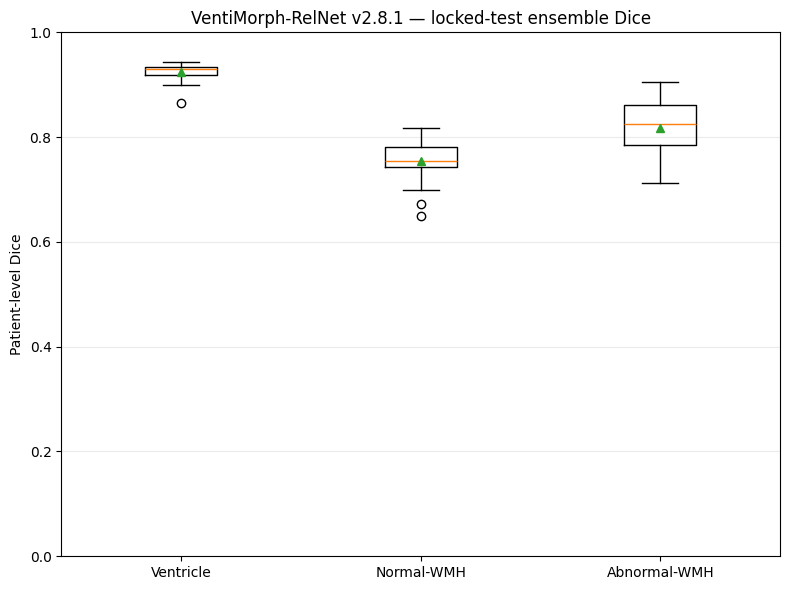

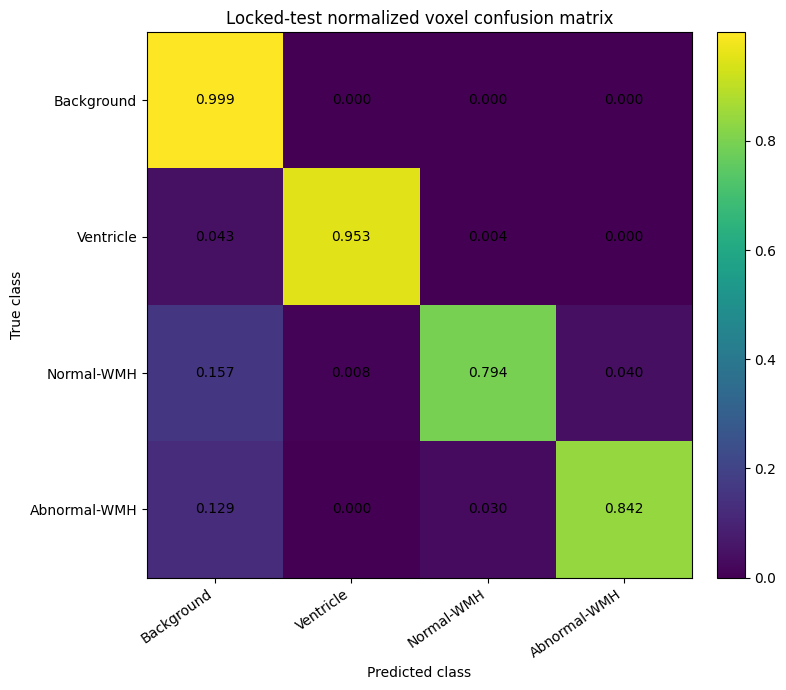

In [20]:
# Locked-test figures.
dice_columns = [
    "ventricle_dice",
    "normal_wmh_dice",
    "abnormal_wmh_dice",
]
dice_labels = [
    "Ventricle",
    "Normal-WMH",
    "Abnormal-WMH",
]

plt.figure(figsize=(8, 6))
plt.boxplot(
    [
        patient_metrics_df[c]
        .dropna()
        .to_numpy()
        for c in dice_columns
    ],
    tick_labels=dice_labels,
    showmeans=True,
)
plt.ylabel("Patient-level Dice")
plt.title(
    "VentiMorph-RelNet v2.8.1 — locked-test ensemble Dice"
)
plt.ylim(0, 1)
plt.grid(
    axis="y",
    alpha=0.25,
)
plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "Figure16_locked_test_dice_boxplot.png",
    dpi=300,
    bbox_inches="tight",
)
plt.savefig(
    FIGURE_DIR / "Figure16_locked_test_dice_boxplot.pdf",
    bbox_inches="tight",
)
plt.show()


cm = global_confusion.astype(float)
normalized_cm = cm / np.maximum(
    cm.sum(axis=1, keepdims=True),
    1,
)

plt.figure(figsize=(8, 7))
image = plt.imshow(
    normalized_cm,
    interpolation="nearest",
)
plt.colorbar(
    image,
    fraction=0.046,
    pad=0.04,
)

axis_labels = [
    "Background",
    "Ventricle",
    "Normal-WMH",
    "Abnormal-WMH",
]

plt.xticks(
    range(4),
    axis_labels,
    rotation=35,
    ha="right",
)
plt.yticks(
    range(4),
    axis_labels,
)

plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.title(
    "Locked-test normalized voxel confusion matrix"
)

for r in range(4):
    for c in range(4):
        plt.text(
            c,
            r,
            f"{normalized_cm[r, c]:.3f}",
            ha="center",
            va="center",
        )

plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "Figure17_locked_test_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight",
)
plt.savefig(
    FIGURE_DIR / "Figure17_locked_test_confusion_matrix.pdf",
    bbox_inches="tight",
)
plt.show()


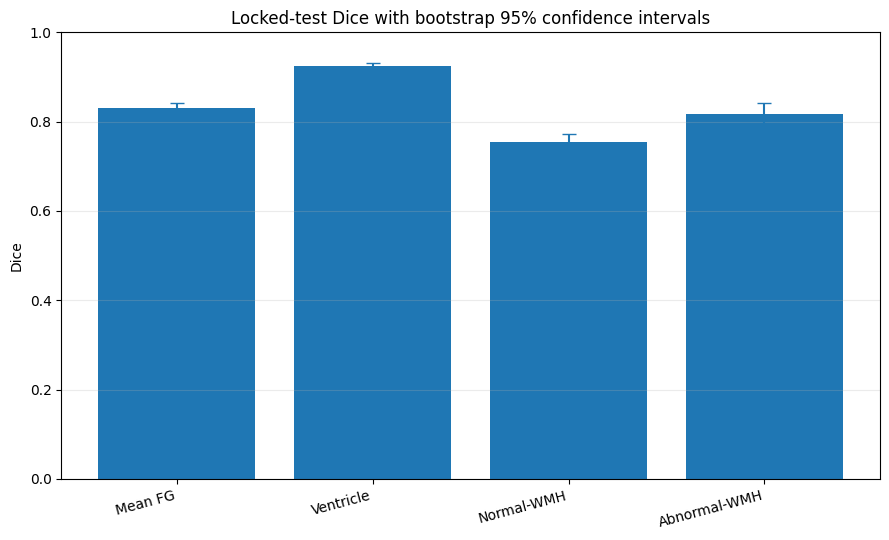

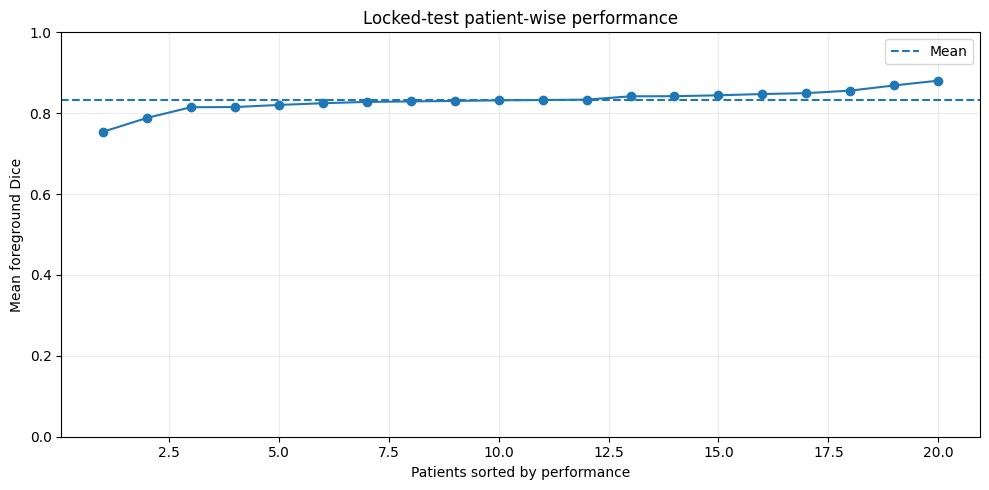

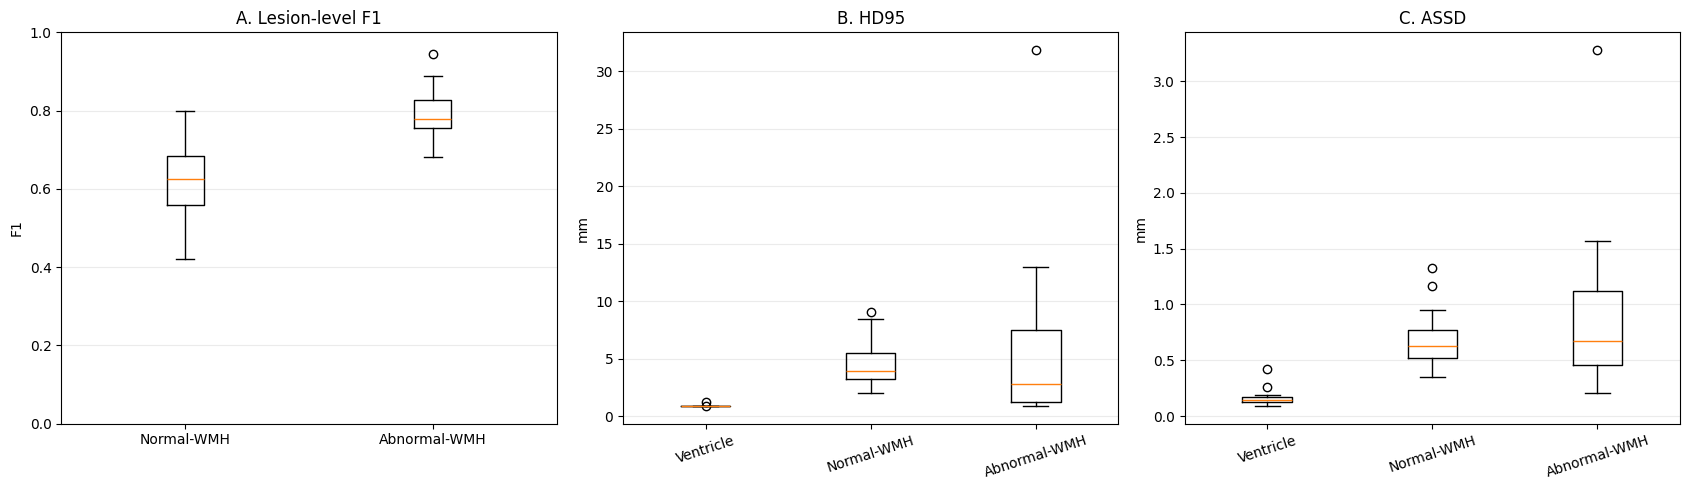

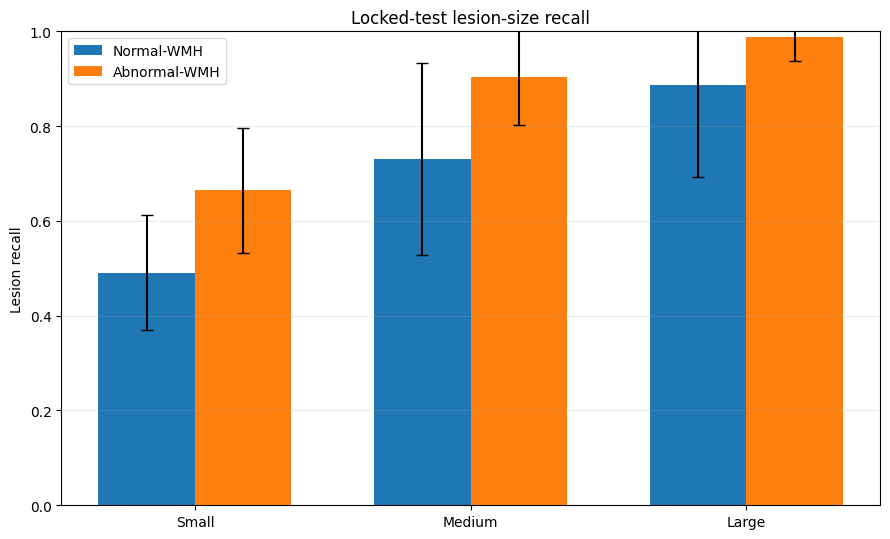

/tmp/ipykernel_58/525605581.py:185: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  pr_auc = float(np.trapz(
/tmp/ipykernel_58/525605581.py:189: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  roc_auc = float(np.trapz(


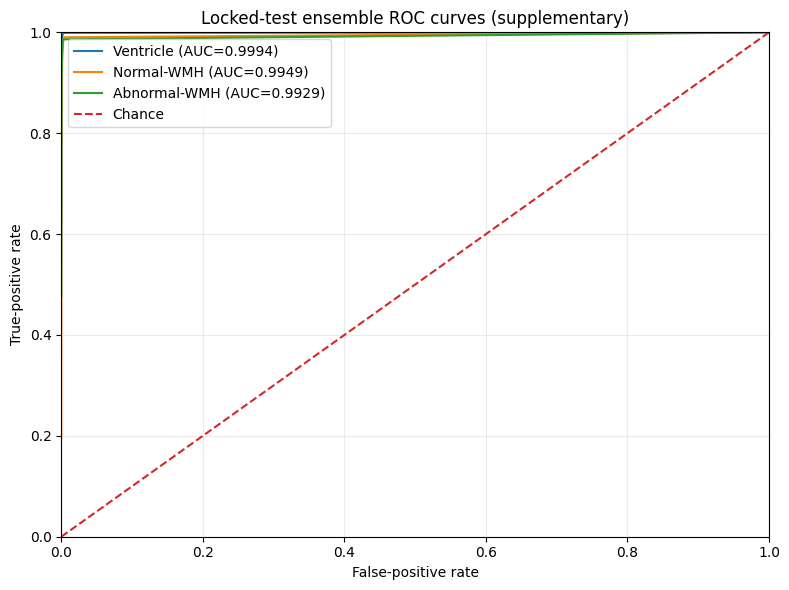

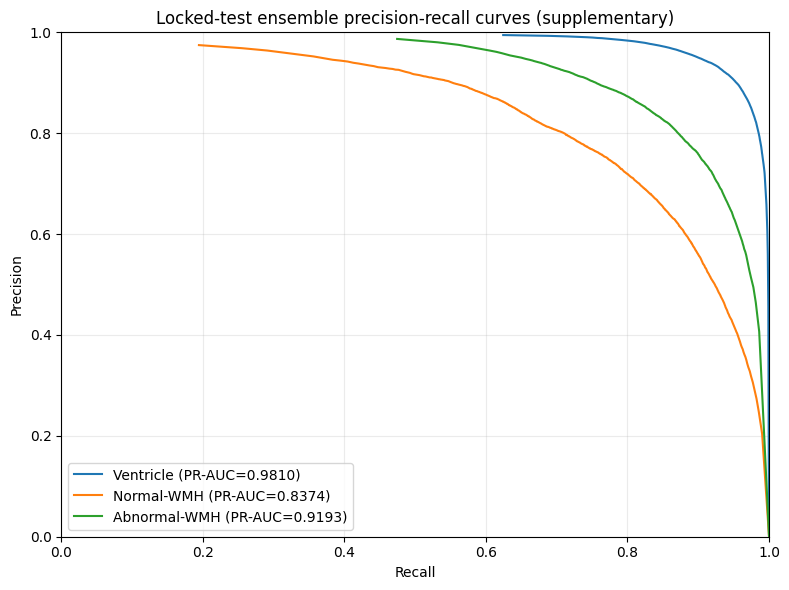

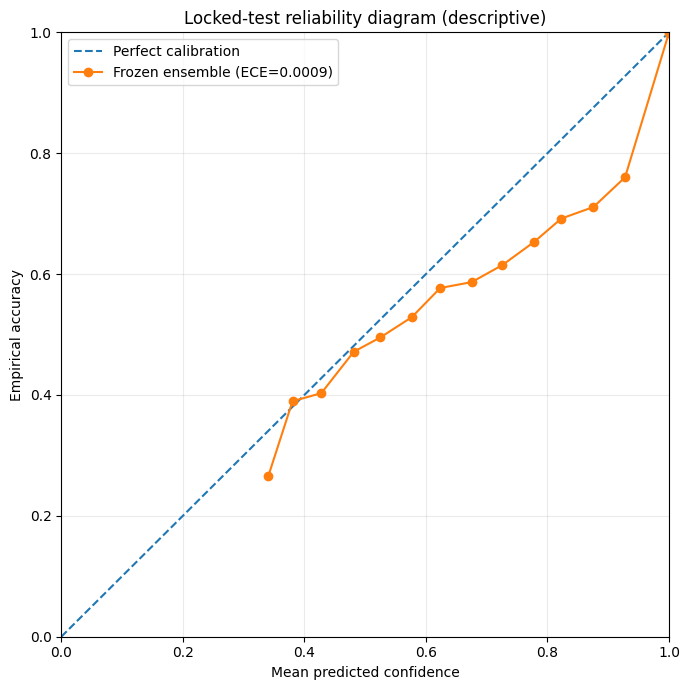

Supplementary locked-test probability metrics:


,class_id,class,pr_auc_approx,roc_auc_approx,positive_voxels,negative_voxels
0,1,Ventricle,0.981015,0.999440,107911,25975417
1,2,Normal-WMH,0.837417,0.994862,29093,26054235
2,3,Abnormal-WMH,0.919269,0.992908,45683,26037645


Locked-test descriptive ECE: 0.000866945550370784
Locked-test descriptive Brier: 0.00259362999011881


In [21]:

# ---------------------------------------------------------------------
# Additional publication-oriented locked-test visualization
# ---------------------------------------------------------------------

# Primary Dice + bootstrap 95% CI
ci_metrics = [
    ("mean_foreground_dice", "Mean FG"),
    ("ventricle_dice", "Ventricle"),
    ("normal_wmh_dice", "Normal-WMH"),
    ("abnormal_wmh_dice", "Abnormal-WMH"),
]

ci_rows = []
for metric, label in ci_metrics:
    r = bootstrap_ci_df[bootstrap_ci_df["metric"] == metric]
    if len(r) != 1:
        continue
    r = r.iloc[0]
    ci_rows.append({
        "metric": label,
        "mean": r["mean"],
        "low": r["ci95_lower"],
        "high": r["ci95_upper"],
    })

ci_plot_df = pd.DataFrame(ci_rows)
x = np.arange(len(ci_plot_df))
means = ci_plot_df["mean"].to_numpy()
low = ci_plot_df["low"].to_numpy()
high = ci_plot_df["high"].to_numpy()

plt.figure(figsize=(9, 5.5))
plt.bar(x, means)
plt.errorbar(
    x,
    means,
    yerr=np.vstack([means - low, high - means]),
    fmt="none",
    capsize=5,
)
plt.xticks(x, ci_plot_df["metric"], rotation=15, ha="right")
plt.ylabel("Dice")
plt.ylim(0, 1)
plt.title("Locked-test Dice with bootstrap 95% confidence intervals")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "Figure18_locked_test_Dice_95CI.png", dpi=300, bbox_inches="tight")
plt.savefig(FIGURE_DIR / "Figure18_locked_test_Dice_95CI.pdf", bbox_inches="tight")
plt.show()

# Patient-wise sorted mean FG Dice
ordered = patient_metrics_df.sort_values("mean_foreground_dice").reset_index(drop=True)
plt.figure(figsize=(10, 5))
plt.plot(
    np.arange(1, len(ordered) + 1),
    ordered["mean_foreground_dice"],
    marker="o",
)
plt.axhline(
    patient_metrics_df["mean_foreground_dice"].mean(),
    linestyle="--",
    label="Mean",
)
plt.xlabel("Patients sorted by performance")
plt.ylabel("Mean foreground Dice")
plt.ylim(0, 1)
plt.title("Locked-test patient-wise performance")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.savefig(FIGURE_DIR / "Figure19_locked_test_patientwise_Dice.png", dpi=300, bbox_inches="tight")
plt.savefig(FIGURE_DIR / "Figure19_locked_test_patientwise_Dice.pdf", bbox_inches="tight")
plt.show()

ordered[["patient_id", "mean_foreground_dice"]].to_csv(
    TABLE_DIR / "locked_test_patientwise_sorted_mean_fg_dice.csv",
    index=False,
)

# Lesion-level F1 and surface distances
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

axes[0].boxplot(
    [
        patient_metrics_df["normal_wmh_lesion_f1"].dropna(),
        patient_metrics_df["abnormal_wmh_lesion_f1"].dropna(),
    ],
    tick_labels=["Normal-WMH", "Abnormal-WMH"],
)
axes[0].set_title("A. Lesion-level F1")
axes[0].set_ylabel("F1")
axes[0].set_ylim(0, 1)
axes[0].grid(axis="y", alpha=0.25)

axes[1].boxplot(
    [
        patient_metrics_df["ventricle_hd95_mm"].replace([np.inf, -np.inf], np.nan).dropna(),
        patient_metrics_df["normal_wmh_hd95_mm"].replace([np.inf, -np.inf], np.nan).dropna(),
        patient_metrics_df["abnormal_wmh_hd95_mm"].replace([np.inf, -np.inf], np.nan).dropna(),
    ],
    tick_labels=["Ventricle", "Normal-WMH", "Abnormal-WMH"],
)
axes[1].set_title("B. HD95")
axes[1].set_ylabel("mm")
axes[1].tick_params(axis="x", rotation=18)
axes[1].grid(axis="y", alpha=0.25)

axes[2].boxplot(
    [
        patient_metrics_df["ventricle_assd_mm"].replace([np.inf, -np.inf], np.nan).dropna(),
        patient_metrics_df["normal_wmh_assd_mm"].replace([np.inf, -np.inf], np.nan).dropna(),
        patient_metrics_df["abnormal_wmh_assd_mm"].replace([np.inf, -np.inf], np.nan).dropna(),
    ],
    tick_labels=["Ventricle", "Normal-WMH", "Abnormal-WMH"],
)
axes[2].set_title("C. ASSD")
axes[2].set_ylabel("mm")
axes[2].tick_params(axis="x", rotation=18)
axes[2].grid(axis="y", alpha=0.25)

fig.tight_layout()
fig.savefig(FIGURE_DIR / "Figure20_locked_test_lesion_and_surface_metrics.png", dpi=300, bbox_inches="tight")
fig.savefig(FIGURE_DIR / "Figure20_locked_test_lesion_and_surface_metrics.pdf", bbox_inches="tight")
plt.show()

# Lesion-size recall
size_rows = []
for prefix, label in [("normal_wmh", "Normal-WMH"), ("abnormal_wmh", "Abnormal-WMH")]:
    for size in ["small", "medium", "large"]:
        col = f"{prefix}_{size}_lesion_recall"
        vals = pd.to_numeric(patient_metrics_df[col], errors="coerce").dropna()
        size_rows.append({
            "class": label,
            "size": size.capitalize(),
            "mean": vals.mean(),
            "sd": vals.std(ddof=1),
            "n": len(vals),
        })

size_df = pd.DataFrame(size_rows)
size_df.to_csv(TABLE_DIR / "locked_test_lesion_size_recall_summary.csv", index=False)

sizes = ["Small", "Medium", "Large"]
normal = size_df[size_df["class"] == "Normal-WMH"].set_index("size").loc[sizes]
abnormal = size_df[size_df["class"] == "Abnormal-WMH"].set_index("size").loc[sizes]

x = np.arange(3)
width = 0.35
plt.figure(figsize=(9, 5.5))
plt.bar(x - width/2, normal["mean"], width, yerr=normal["sd"], capsize=4, label="Normal-WMH")
plt.bar(x + width/2, abnormal["mean"], width, yerr=abnormal["sd"], capsize=4, label="Abnormal-WMH")
plt.xticks(x, sizes)
plt.ylim(0, 1)
plt.ylabel("Lesion recall")
plt.title("Locked-test lesion-size recall")
plt.grid(axis="y", alpha=0.25)
plt.legend()
plt.tight_layout()
plt.savefig(FIGURE_DIR / "Figure21_locked_test_lesion_size_recall.png", dpi=300, bbox_inches="tight")
plt.savefig(FIGURE_DIR / "Figure21_locked_test_lesion_size_recall.pdf", bbox_inches="tight")
plt.show()

# Supplementary frozen-test ROC / PR from ensemble probabilities.
curve_rows = []
auc_rows = []

for class_id, class_name in PROBABILITY_CLASS_NAMES.items():
    pos = positive_hist[class_id]
    neg = negative_hist[class_id]

    total_positive = int(pos.sum())
    total_negative = int(neg.sum())
    tp = np.cumsum(pos[::-1]).astype(np.float64)
    fp = np.cumsum(neg[::-1]).astype(np.float64)

    recall = tp / max(total_positive, 1)
    fpr = fp / max(total_negative, 1)
    precision = tp / np.maximum(tp + fp, 1)

    thresholds = (
        np.arange(PROBABILITY_BINS - 1, -1, -1, dtype=np.float64)
        / PROBABILITY_BINS
    )

    pr_auc = float(np.trapz(
        np.concatenate([[1.0], precision]),
        np.concatenate([[0.0], recall]),
    ))
    roc_auc = float(np.trapz(
        np.concatenate([[0.0], recall]),
        np.concatenate([[0.0], fpr]),
    ))

    auc_rows.append({
        "class_id": class_id,
        "class": class_name,
        "pr_auc_approx": pr_auc,
        "roc_auc_approx": roc_auc,
        "positive_voxels": total_positive,
        "negative_voxels": total_negative,
    })

    for idx in range(len(recall)):
        curve_rows.append({
            "class_id": class_id,
            "class": class_name,
            "threshold": thresholds[idx],
            "precision": precision[idx],
            "recall": recall[idx],
            "fpr": fpr[idx],
            "tpr": recall[idx],
        })

locked_curve_df = pd.DataFrame(curve_rows)
locked_auc_df = pd.DataFrame(auc_rows)
locked_curve_df.to_csv(TABLE_DIR / "locked_test_pr_roc_curves.csv", index=False)
locked_auc_df.to_csv(TABLE_DIR / "locked_test_pr_roc_auc_summary.csv", index=False)

plt.figure(figsize=(8, 6))
for class_name in PROBABILITY_CLASS_NAMES.values():
    d = locked_curve_df[locked_curve_df["class"] == class_name]
    auc_value = locked_auc_df.loc[locked_auc_df["class"] == class_name, "roc_auc_approx"].iloc[0]
    plt.plot(d["fpr"], d["tpr"], label=f"{class_name} (AUC={auc_value:.4f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Chance")
plt.xlabel("False-positive rate")
plt.ylabel("True-positive rate")
plt.title("Locked-test ensemble ROC curves (supplementary)")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.savefig(FIGURE_DIR / "Figure22_locked_test_ROC_curves.png", dpi=300, bbox_inches="tight")
plt.savefig(FIGURE_DIR / "Figure22_locked_test_ROC_curves.pdf", bbox_inches="tight")
plt.show()

plt.figure(figsize=(8, 6))
for class_name in PROBABILITY_CLASS_NAMES.values():
    d = locked_curve_df[locked_curve_df["class"] == class_name]
    auc_value = locked_auc_df.loc[locked_auc_df["class"] == class_name, "pr_auc_approx"].iloc[0]
    plt.plot(d["recall"], d["precision"], label=f"{class_name} (PR-AUC={auc_value:.4f})")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Locked-test ensemble precision-recall curves (supplementary)")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.savefig(FIGURE_DIR / "Figure23_locked_test_PR_curves.png", dpi=300, bbox_inches="tight")
plt.savefig(FIGURE_DIR / "Figure23_locked_test_PR_curves.pdf", bbox_inches="tight")
plt.show()

# Frozen-test calibration (descriptive only; no calibration fitting).
nonempty = calibration_count > 0
mean_confidence = np.divide(
    calibration_confidence_sum,
    calibration_count,
    out=np.full(CALIBRATION_BINS, np.nan),
    where=nonempty,
)
accuracy = np.divide(
    calibration_correct_sum,
    calibration_count,
    out=np.full(CALIBRATION_BINS, np.nan),
    where=nonempty,
)
ece = float(
    np.nansum(
        (calibration_count / max(calibration_count.sum(), 1))
        * np.abs(accuracy - mean_confidence)
    )
)
brier_score = float(brier_sum / max(total_probability_voxels, 1))

pd.DataFrame([{
    "locked_test_voxels": total_probability_voxels,
    "expected_calibration_error": ece,
    "multiclass_brier_score": brier_score,
    "note": "descriptive only; no calibration fitted on locked test",
}]).to_csv(TABLE_DIR / "locked_test_calibration_summary.csv", index=False)

plt.figure(figsize=(7, 7))
plt.plot([0, 1], [0, 1], linestyle="--", label="Perfect calibration")
plt.plot(
    mean_confidence[nonempty],
    accuracy[nonempty],
    marker="o",
    label=f"Frozen ensemble (ECE={ece:.4f})",
)
plt.xlabel("Mean predicted confidence")
plt.ylabel("Empirical accuracy")
plt.title("Locked-test reliability diagram (descriptive)")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.savefig(FIGURE_DIR / "Figure24_locked_test_reliability.png", dpi=300, bbox_inches="tight")
plt.savefig(FIGURE_DIR / "Figure24_locked_test_reliability.pdf", bbox_inches="tight")
plt.show()

print("Supplementary locked-test probability metrics:")
display(locked_auc_df)
print("Locked-test descriptive ECE:", ece)
print("Locked-test descriptive Brier:", brier_score)


In [22]:
# Freeze and document the final test protocol.
final_metadata = {
    "model": "VentiMorph-RelNet-v2.8.1-segmentation-first",
    "stage": "final_locked_test",
    "locked_test_patients": 20,
    "ensemble_members": 5,
    "ensemble_rule": "equal-weight mean softmax probability",
    "decision_rule": "argmax of ensemble mean probability",
    "checkpoint_rule": (
        "best_model.pt from each fold, selected during training "
        "by the pre-existing balanced validation score"
    ),
    "threshold_tuning_on_test": False,
    "calibration_fitted_on_test": False,
    "postprocessing_optimized_on_test": False,
    "retraining_performed": False,
    "split_sha256": EXPECTED_SPLIT_SHA256,
    "bootstrap_ci_replicates": BOOTSTRAP_REPLICATES,
    "bootstrap_seed": BOOTSTRAP_SEED,
    "scientific_note": (
        "The locked-test result is final under this frozen inference rule. "
        "Do not alter model, thresholds, ensemble weights, or post-processing "
        "after observing these results."
    ),
}

(OUTPUT_DIR / "final_locked_test_metadata.json").write_text(
    json.dumps(
        final_metadata,
        indent=2,
    ),
    encoding="utf-8",
)

archive_path = shutil.make_archive(
    "/kaggle/working/MS3SEG_V281_FINAL_LOCKED_TEST_COMPLETE_VISUALIZATION_RESULTS",
    "zip",
    root_dir=OUTPUT_DIR,
)

print("\nFINAL LOCKED-TEST EVALUATION COMPLETE")
print("Download:")
print(
    "/kaggle/working/"
    "MS3SEG_V281_FINAL_LOCKED_TEST_COMPLETE_VISUALIZATION_RESULTS.zip"
)
print()
print(
    "Protocol is now frozen. Do not tune the model or inference rule "
    "using these test results."
)



FINAL LOCKED-TEST EVALUATION COMPLETE
Download:
/kaggle/working/MS3SEG_V281_FINAL_LOCKED_TEST_COMPLETE_VISUALIZATION_RESULTS.zip

Protocol is now frozen. Do not tune the model or inference rule using these test results.
